In [41]:
import jax
import jax.numpy as jnp
import blackjax
from blackjax.ns.utils import finalise
import tqdm

rng_key = jax.random.PRNGKey(0)

loglikelihood_fn = lambda x: jax.scipy.stats.multivariate_normal.logpdf(
    x, jnp.ones(5), jnp.eye(5) * 0.01
)
logprior_fn = lambda x: jax.scipy.stats.multivariate_normal.logpdf(
    x, jnp.zeros(5), jnp.eye(5)
)

algo = blackjax.nss(
    logprior_fn=logprior_fn,
    loglikelihood_fn=loglikelihood_fn,
    num_delete=50,
    num_inner_steps=20,
)

rng_key, initialization_key = jax.random.split(rng_key)
live = algo.init(jax.random.normal(initialization_key, (1000, 5)))
step = jax.jit(algo.step)

dead_points = []

with tqdm.tqdm(desc="Dead points", unit=" dead points") as pbar:
    while not live.integrator.logZ_live - live.integrator.logZ < -3:
        rng_key, subkey = jax.random.split(rng_key)
        live, dead = step(subkey, live)
        dead_points.append(dead)
        pbar.update(len(dead.particles.loglikelihood))

ns_run = finalise(live, dead_points)

Dead points: 16250 dead points [00:28, 563.47 dead points/s] 


In [42]:
ns_run.particles.position.shape

(17250, 5)

In [43]:
import anesthetic

nested_samples = anesthetic.NestedSamples(
    data=ns_run.particles.position,
    logL=ns_run.particles.loglikelihood,
    logL_birth=ns_run.particles.loglikelihood_birth,
    )

In [44]:
print(nested_samples.shape)
print(nested_samples.columns)

(17250, 8)
Index([0, 1, 2, 3, 4, 'logL', 'logL_birth', 'nlive'], dtype='object')


IndexError: index 2 is out of bounds for axis 0 with size 2

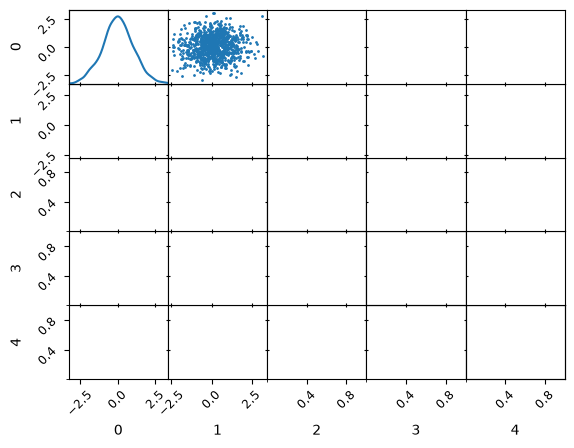

In [45]:
prior = nested_samples.set_beta(0.0).plot_2d(range(5), label="prior")
post = nested_samples.plot_2d(prior, label="posterior")
prior.iloc[-1, 0].legend(bbox_to_anchor=(len(prior), len(prior)), loc='lower right')

## Walkthrough of nested sampling

In [ ]:
import jax
import jax.numpy as jnp
import tqdm

import blackjax

rng_key = jax.random.PRNGKey(0)

d = 20

C = jax.random.normal(rng_key, (d, d)) * 0.1
like_cov = C @ C.T
like_mean = jax.random.normal(rng_key, (d,))

prior_mean = jnp.zeros(d)
prior_cov = jnp.eye(d) * 1

In [ ]:
logprior_density = lambda x: jax.scipy.stats.multivariate_normal.logpdf(
    x, prior_mean, prior_cov
)

loglikelihood_function = lambda x: jax.scipy.stats.multivariate_normal.logpdf(
    x, like_mean, like_cov
)

rng_key, prior_sample_key = jax.random.split(rng_key)
n_live = 1000
initial_population = jax.random.multivariate_normal(
    prior_sample_key, prior_mean, prior_cov, (n_live,)
)

In [ ]:
num_inner_steps = 3 * d
num_delete = int(n_live*0.1)

algo = blackjax.nss(
    logprior_fn=logprior_density,
    loglikelihood_fn=loglikelihood_function,
    num_delete=num_delete,
    num_inner_steps=num_inner_steps,
)

state = algo.init(initial_population)

In [ ]:
from blackjax.ns.base import NSState
print(f"{NSState.__doc__}")
from blackjax.ns.base import NSInfo
print(f"{NSInfo.__doc__}")

State of the Nested Sampler.

At the most basic level, this is just a wrapper around a ``StateWithLogLikelihood``;
richer NS implementations (e.g. ``AdaptiveNSState``) carry extra fields.

Attributes
----------
particles
    The ``StateWithLogLikelihood`` of the current live particles.

Additional information returned at each step of the Nested Sampling algorithm.

Attributes
----------
particles
    The StateWithLogLikelihood of particles that were marked as "dead" (replaced).
update_info
    A NamedTuple (or any PyTree) containing information from the update step
    (inner kernel) used to generate new live particles.



In [ ]:
@jax.jit
def one_step(carry, xs):
    state, k = carry
    k, subk = jax.random.split(k, 2)
    state, dead_point = algo.step(subk, state)
    return (state, k), dead_point

In [ ]:
dead = []

with tqdm.tqdm(desc="Dead points", unit=" dead points") as pbar:
    while not state.integrator.logZ_live - state.integrator.logZ < -3:
        (state, rng_key), dead_info = one_step((state, rng_key), None)
        dead.append(dead_info)
        pbar.update(num_delete)

Dead points: 41600 dead points [00:09, 4223.81 dead points/s]
